# Normal prompt sampling: 2,000 fresh agents

**Complete: 2,000 of 2,000 responses recorded in this snapshot.**

**Requested distribution: mean 10, standard deviation 2 (variance 4).**

Each sampler receives this exact prompt:

> Sample a number from the normal distribution N(10,2), where the mean is 10 and the standard deviation is 2. Respond only with the number and nothing else:

Every response comes from a separate `collaboration.spawn_agent` call with `fork_turns="none"`, with no model or reasoning override. Samplers receive no coordinator conversation history or previous responses, but retain the session's system/developer instructions and tool access. Fresh contexts do not establish statistical independence. Sampling methods and decoding settings are not controlled.

The target was reduced from 5,000 to 2,000 during collection. All responses already collected were retained, and exact final quotas were assigned before drawing the remainder. Sample IDs retain their original planning numbers and are not contiguous. The earlier 200-response experiment is separate. Duplicates and malformed responses remain in the raw data; only valid finite numbers are plotted.

Run from `notebooks/` with NumPy and Matplotlib installed. Re-running this notebook reads the saved data; it does not launch agents.

Public copy: original numerical replies and grouping are preserved. Provider URLs, private paths, and transport-error details are omitted; public file hashes are recomputed. Run `python prepare_data.py` from the repository root before executing this notebook. See the root README for provenance and reproduction steps.

In [1]:
%matplotlib inline
import hashlib
import json
import math
import re
import statistics
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

data_dir = Path("agent_normal_sampling_2000_data")
metadata = json.loads((data_dir / "metadata.json").read_text())
raw_bytes = (data_dir / "responses.jsonl").read_bytes()
assert hashlib.sha256(raw_bytes).hexdigest() == metadata["responses_sha256"]
records = [json.loads(line) for line in raw_bytes.decode().splitlines() if line.strip()]
ids = [r["sample_id"] for r in records]
agent_names = [r["agent_name"] for r in records]
assert len(ids) == len(set(ids)) == len(set(agent_names))
assert all(1 <= sample_id <= metadata["original_planned_count"] for sample_id in ids)
assert set(ids).issubset(set(metadata["final_expected_sample_ids"]))
assert len(records) == metadata["recorded_count"]
if metadata["status"] == "complete":
    assert len(records) == metadata["requested_count"] == 2000
    assert set(ids) == set(metadata["final_expected_sample_ids"])
number = re.compile(r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?")
valid_values = []
invalid_records = []
for record in records:
    raw = record["raw_response"].strip()
    value = float(raw) if number.fullmatch(raw) else None
    if value is not None and math.isfinite(value):
        assert value == record["value"]
        valid_values.append(value)
    else:
        assert record["value"] is None
        invalid_records.append(record)
values = np.asarray(valid_values, dtype=float)
assert len(values) == metadata["valid_count"]
print(f"Snapshot status: {metadata['status']}")
print(f"Recorded: {len(records):,} / 2,000; plotted: {len(values):,}; invalid: {len(invalid_records)}")
print(f"Data SHA-256: {metadata['responses_sha256']}")


Snapshot status: complete
Recorded: 2,000 / 2,000; plotted: 2,000; invalid: 0
Data SHA-256: f3dd7fac2c088d24ca5e8a6344f70af9214ffee12f014b63009e1a70ce7dbfb0


In [2]:
sample_mean = statistics.mean(values.tolist())
sample_sd = statistics.stdev(values.tolist())
assert math.isclose(sample_mean, float(values.mean()), rel_tol=1e-12)
assert math.isclose(sample_sd, float(values.std(ddof=1)), rel_tol=1e-12)
print(f"Observed mean: {sample_mean:.6f} (target: 10)")
print(f"Observed sample SD: {sample_sd:.6f} (target: 2; ddof=1)")
print(f"Range: [{values.min():.6f}, {values.max():.6f}]")
print(f"Distinct numeric values: {len(set(values)):,}")
print("Most frequent values:")
for value, count in Counter(values.tolist()).most_common(10):
    print(f"  {value:g}: {count} ({count / len(values):.1%})")


Observed mean: 10.498965 (target: 10)
Observed sample SD: 1.229278 (target: 2; ddof=1)
Range: [4.443711, 16.533339]
Distinct numeric values: 303
Most frequent values:
  11.37: 245 (12.2%)
  8.73: 115 (5.8%)
  11.374: 109 (5.5%)
  11.2847: 90 (4.5%)
  11.3728: 71 (3.5%)
  11.372: 65 (3.2%)
  11.3729: 57 (2.9%)
  8.7314: 49 (2.5%)
  11.3748: 46 (2.3%)
  11.3827: 45 (2.2%)


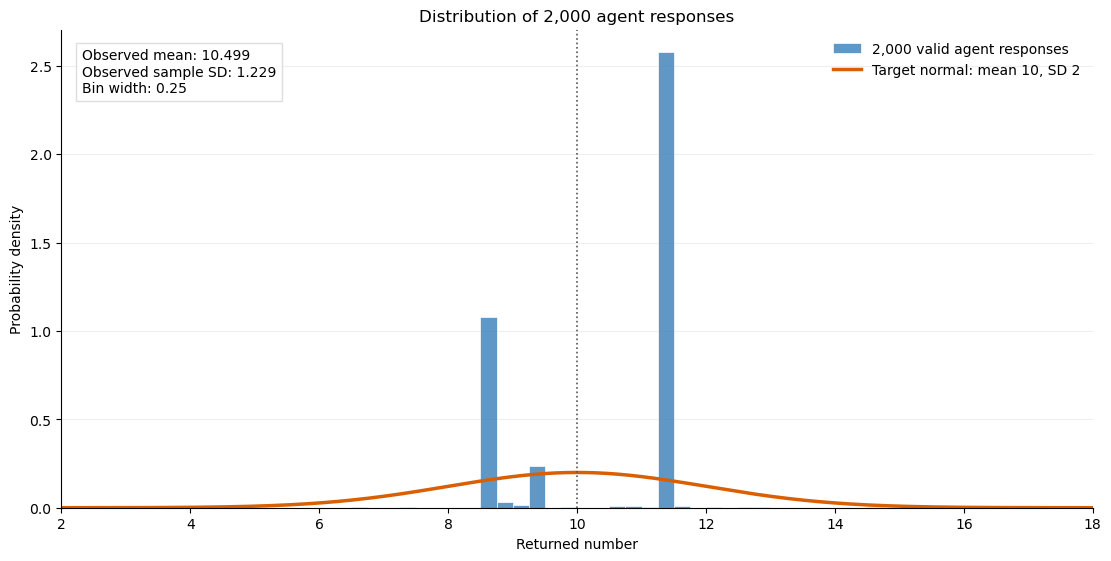

In [3]:
bin_width = 0.25
left = min(2.0, np.floor(values.min() / bin_width) * bin_width)
right = max(18.0, np.ceil(values.max() / bin_width) * bin_width)
bins = np.arange(left, right + bin_width, bin_width)
counts, _ = np.histogram(values, bins=bins)
assert counts.sum() == len(values)
x = np.linspace(left, right, 1500)
target_density = np.exp(-0.5 * ((x - 10) / 2) ** 2) / (2 * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
heights, edges, _ = ax.hist(values, bins=bins, density=True, color="#377eb8",
                           alpha=0.8, edgecolor="white", linewidth=0.6,
                           label=f"{len(values):,} valid agent responses")
assert np.isclose(np.sum(heights * np.diff(edges)), 1.0)
ax.plot(x, target_density, color="#d95f02", linewidth=2.5, label="Target normal: mean 10, SD 2")
ax.axvline(10, color="#555555", linestyle=":", linewidth=1.2)
suffix = "" if metadata["status"] == "complete" else " (collection in progress)"
ax.set(title=f"Distribution of {len(values):,} agent responses{suffix}",
       xlabel="Returned number", ylabel="Probability density", xlim=(left, right))
ax.text(0.02, 0.96, f"Observed mean: {sample_mean:.3f}\nObserved sample SD: {sample_sd:.3f}\nBin width: {bin_width:g}",
        transform=ax.transAxes, va="top", bbox={"facecolor": "white", "edgecolor": "#dddddd", "alpha": 0.95})
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()


The orange curve is the requested normal distribution, not a fit to the responses. Histogram area is 1. Raw agent IDs, original response text, and collection timestamps are in `agent_normal_sampling_2000_data/responses.jsonl`; collection settings and the data checksum are in `metadata.json`. Four timestamps (sample IDs 189, 190, 3652, and 3653) record recovery time after coordinator bookkeeping issues; their original numeric responses were recovered unchanged.